## Introduction and Lesson Outline

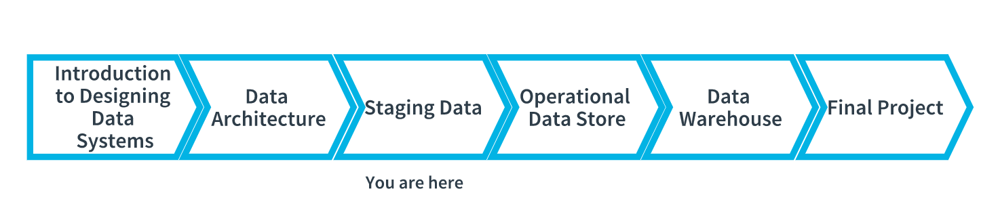

https://www.youtube.com/watch?v=90mRpGFDjV4

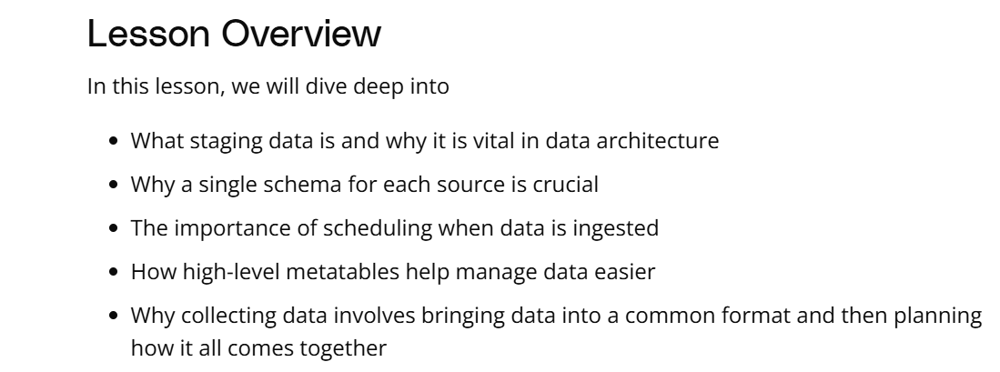

## What is a Staging Database?

https://www.youtube.com/watch?v=0WP1SLWp1qo

Staging is where all the data sources are collected and prepared for ingesting into the ODS system.

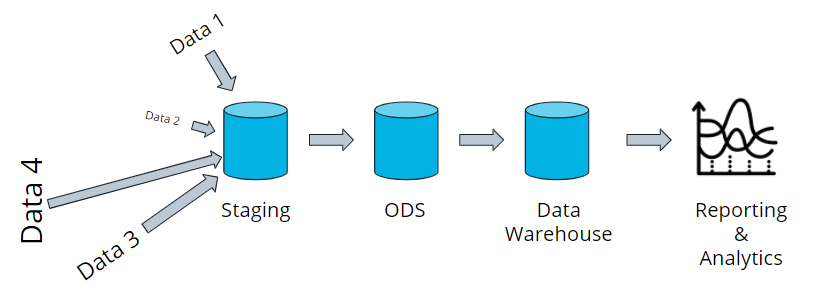

Typical Data Architecture

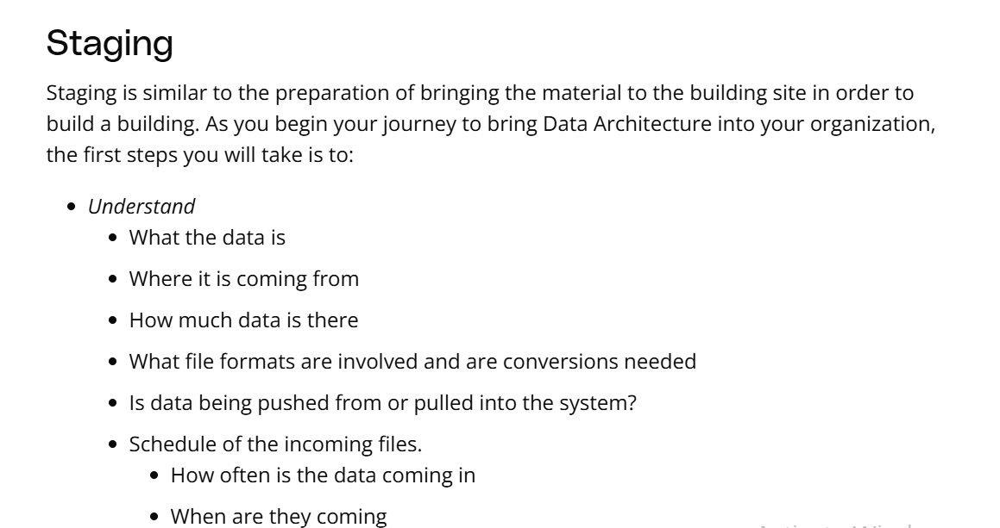

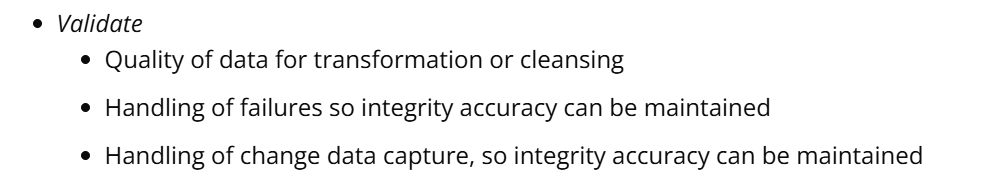

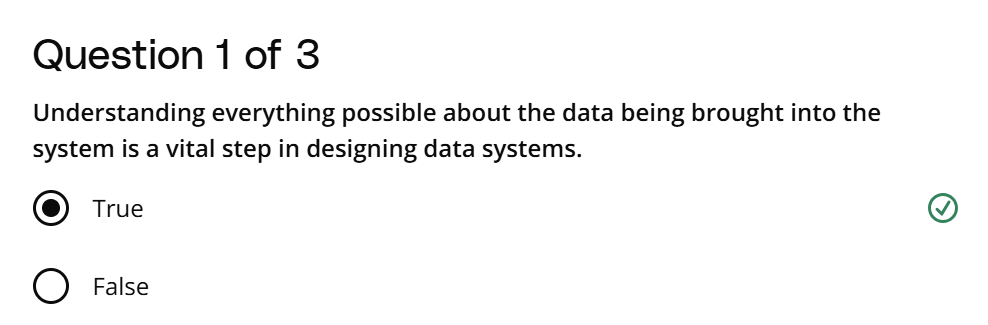

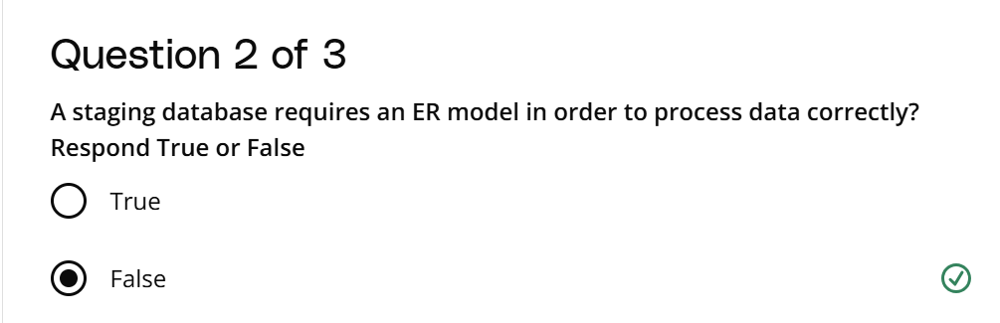

## Question 3 of 3
A Wallstreet trading company has a front office, middle office, and back-office operations. The front office has a trading platform, the middle office has finance operations and the back office maintains complaints and regulatory operations. Which data collection timing strategy is appropriate for each office?

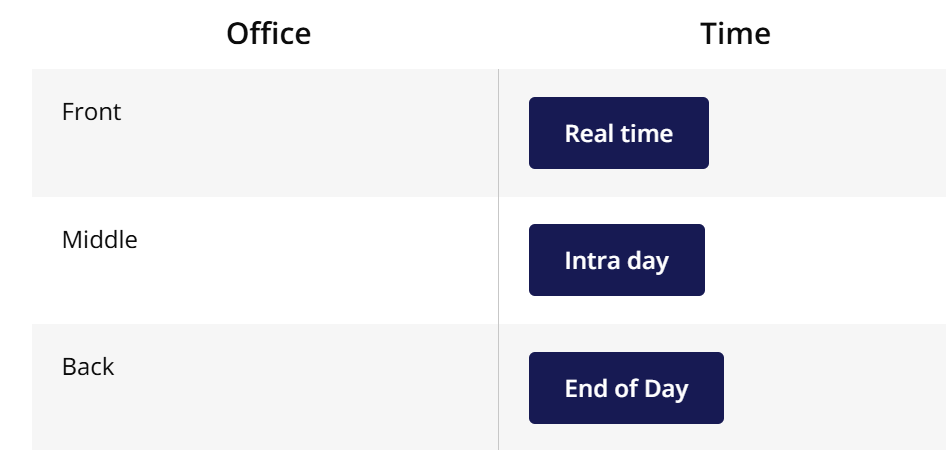

## Why Staging Matters?

https://www.youtube.com/watch?v=IG9YNAOFxMc

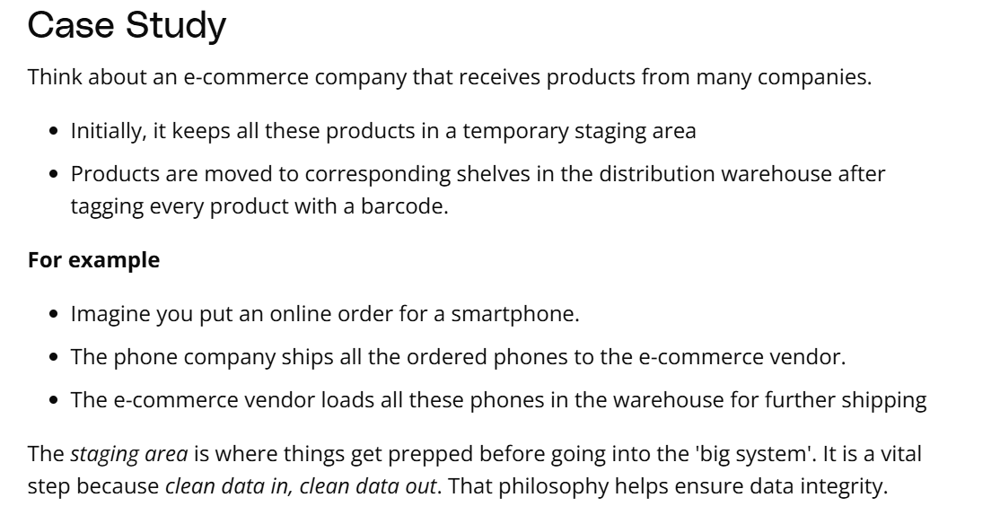

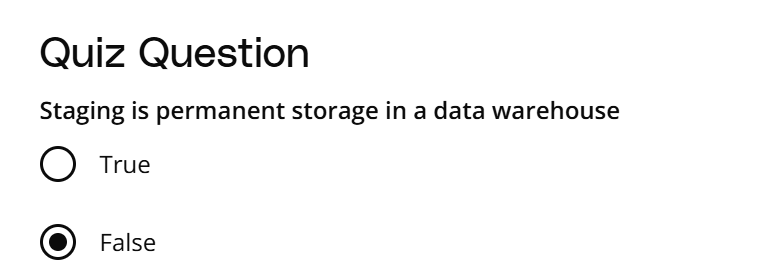

## Create a Staging Database

https://www.youtube.com/watch?v=bUal9jZitmQ

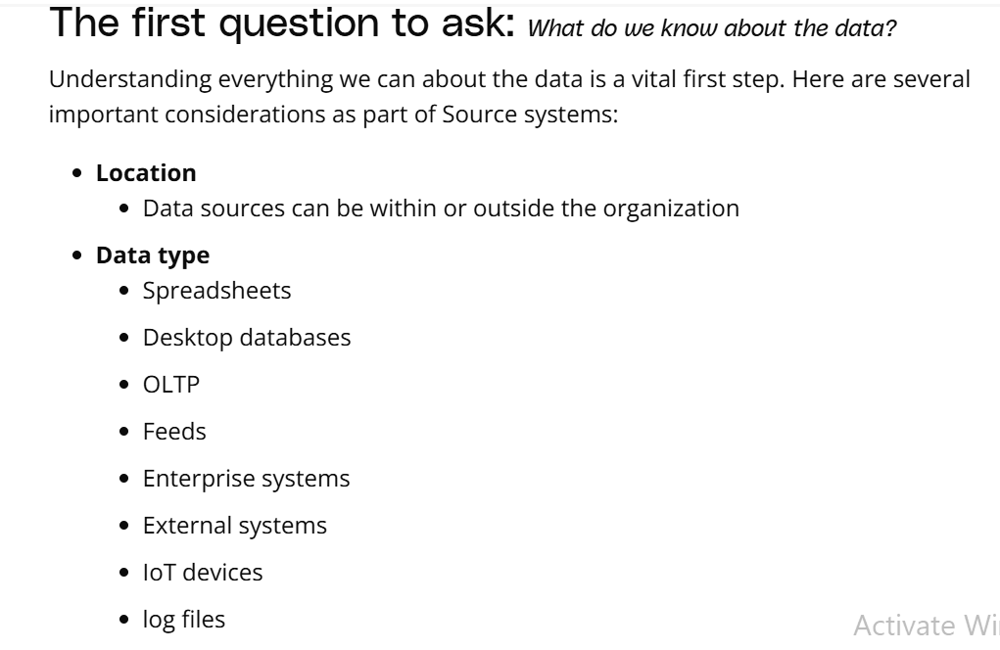

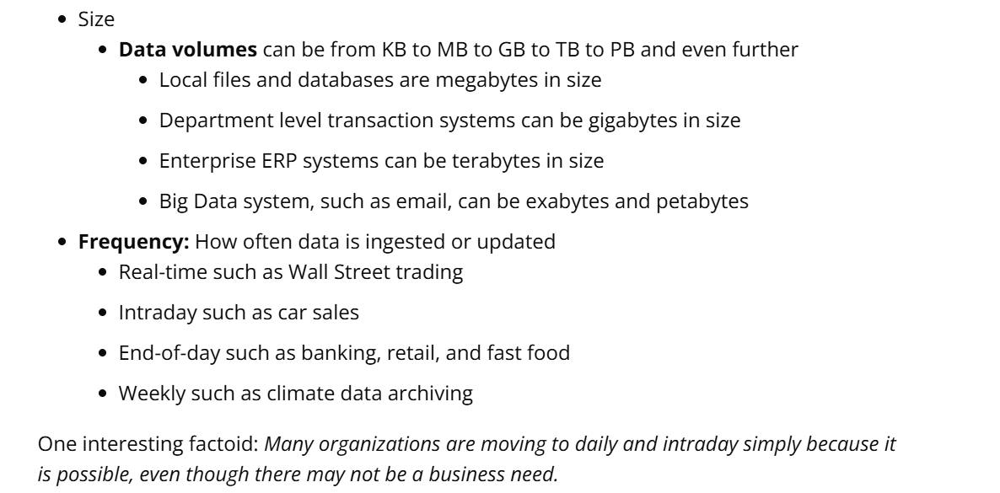

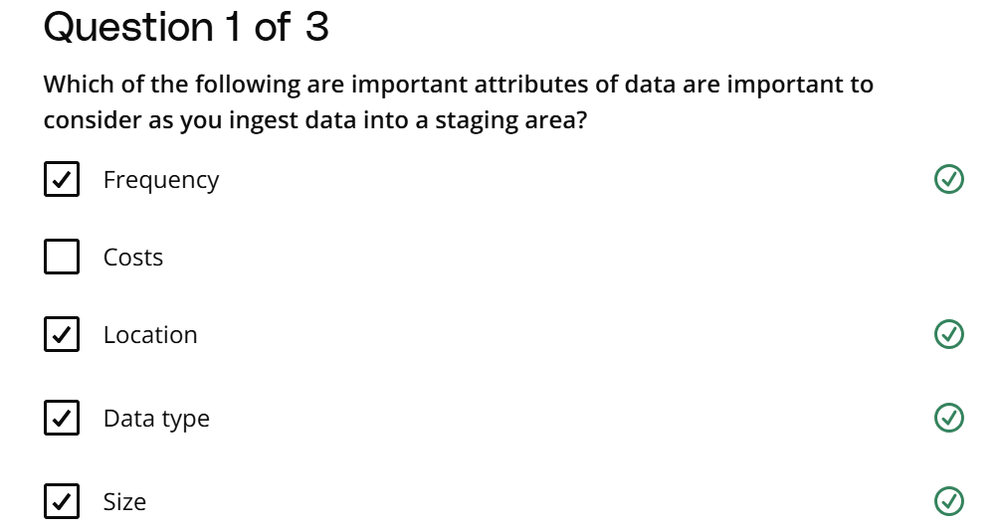

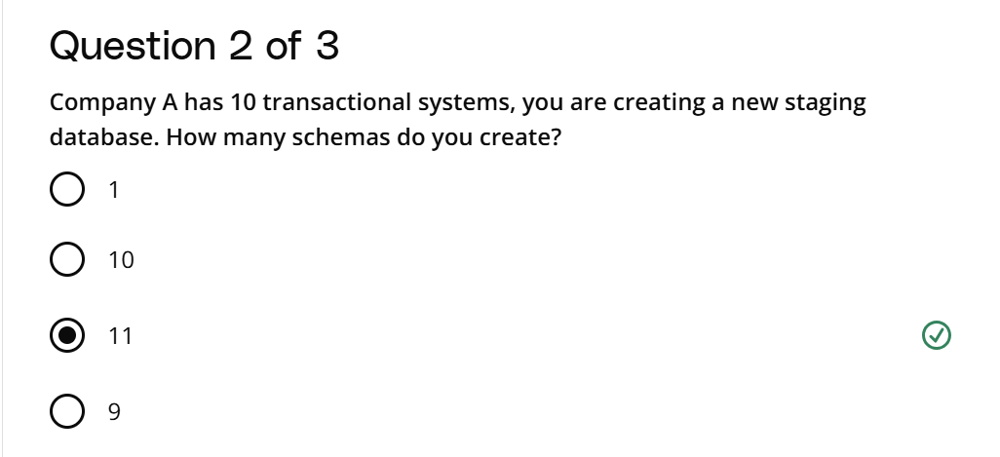

Question 3 of 3

Match the data type with an appropriate frequency of ingestion

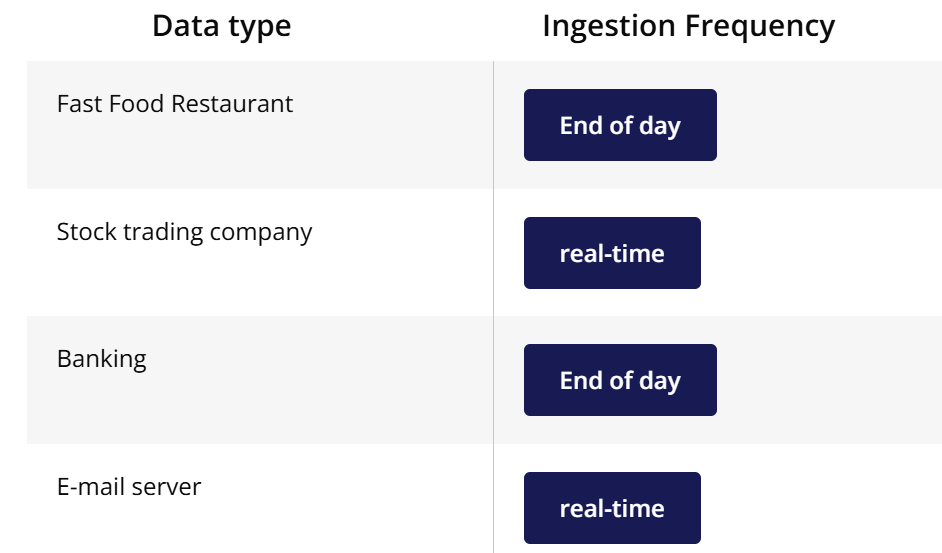

## Create Schema

https://www.youtube.com/watch?v=i_qHq4C9KmY

What is a schema?

A database table that provides a logical grouping of data tables using ER, or Entity-Relationship, models.

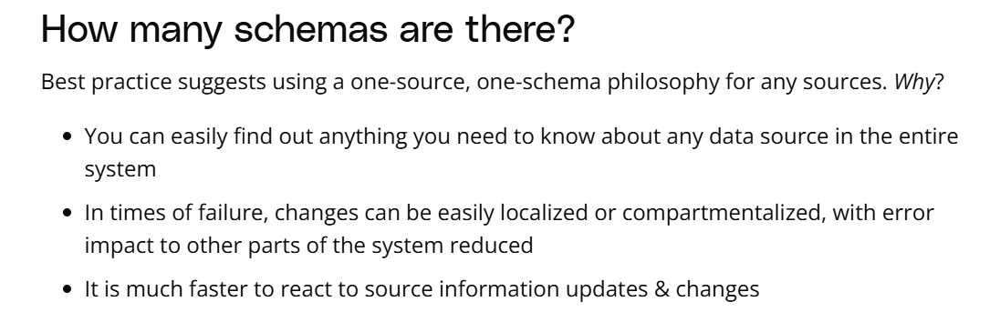

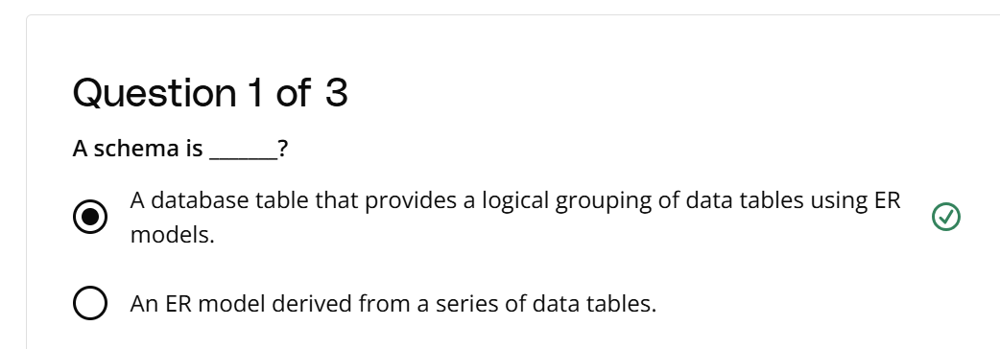

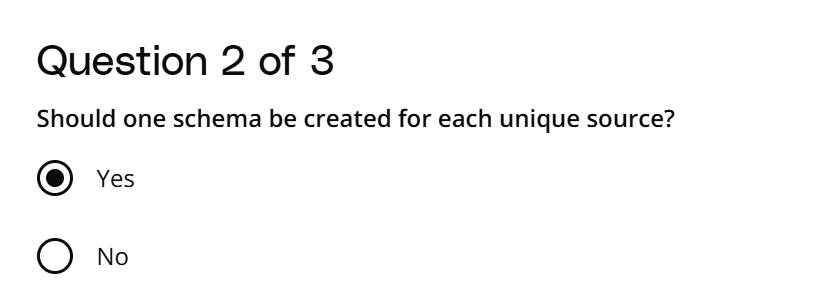

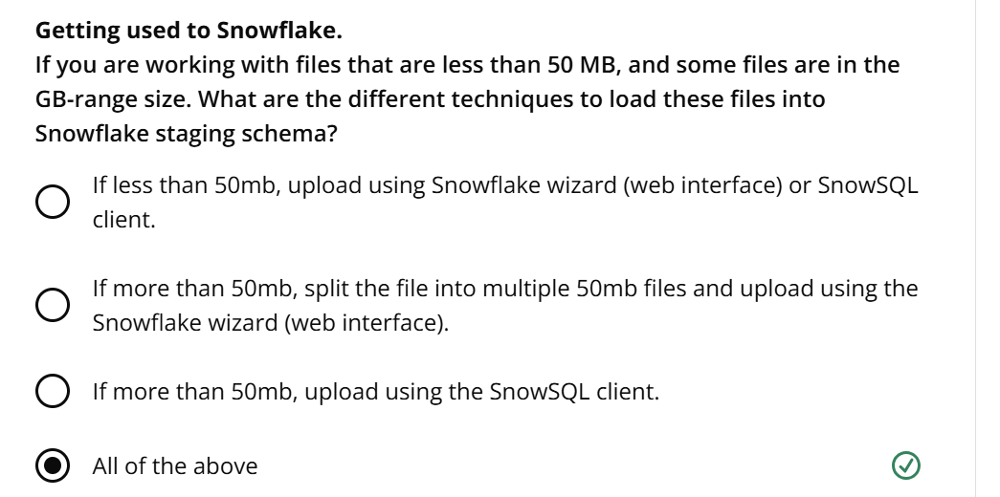

## Demo: Snowflake Database and Schemas

### Creating Schemas in the Snowflake browser

https://www.youtube.com/watch?v=djbHTCsXqGM

## Demo: Loading Small Files using Snowflake in the browser

https://www.youtube.com/watch?v=xT0t9nCaxBQ

## Demo: Loading data with the Snowflake Client

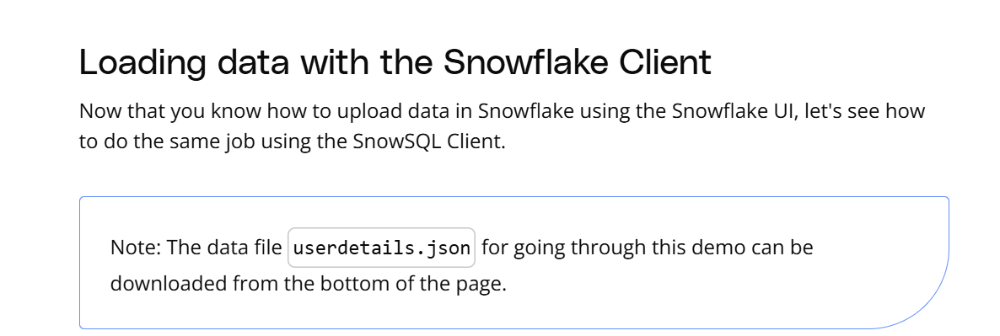

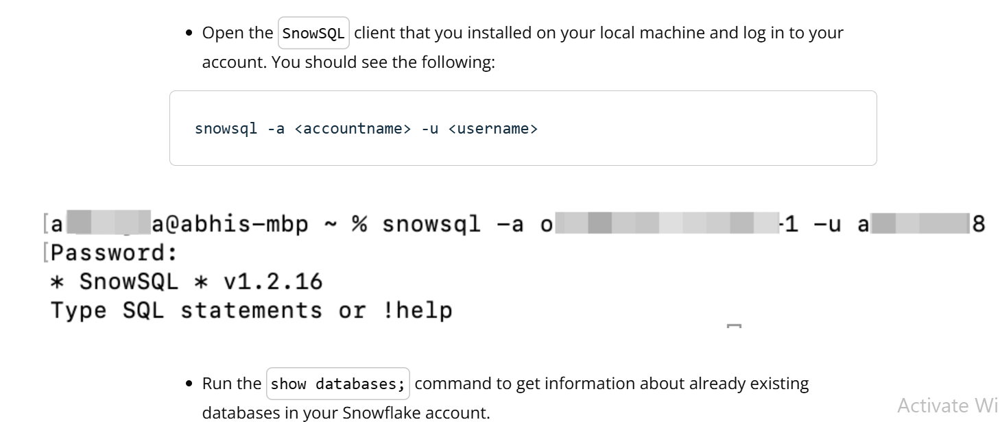

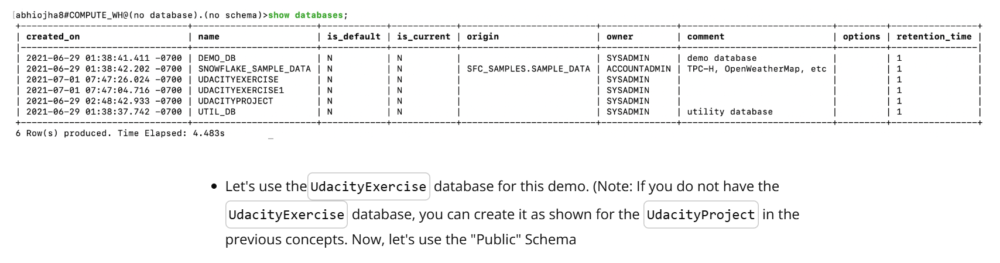

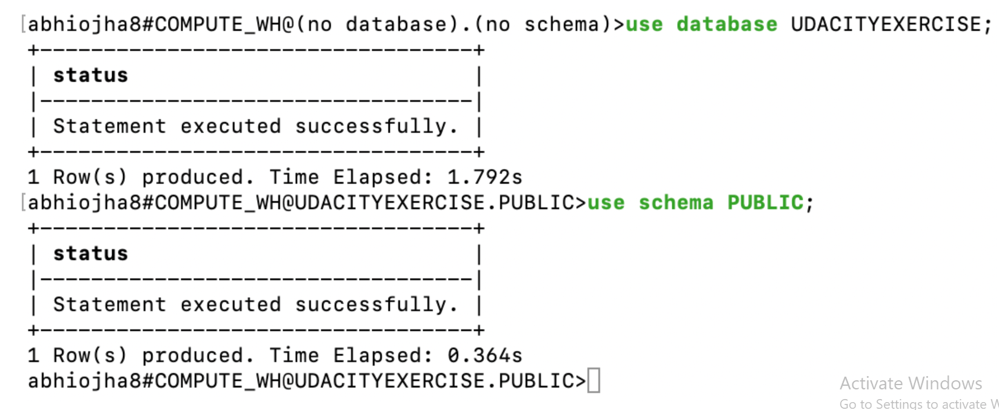

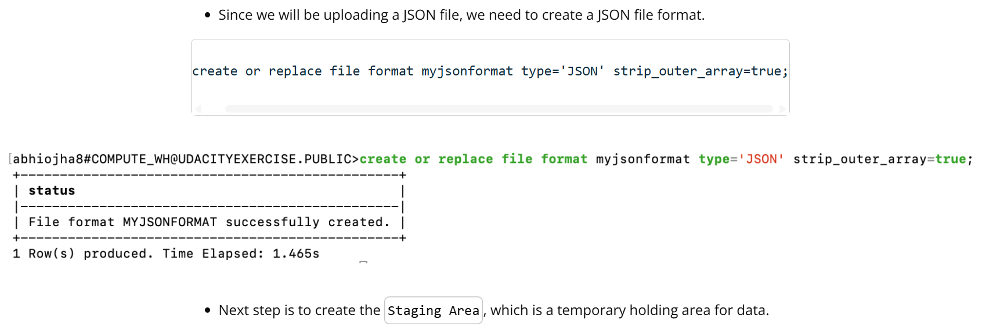

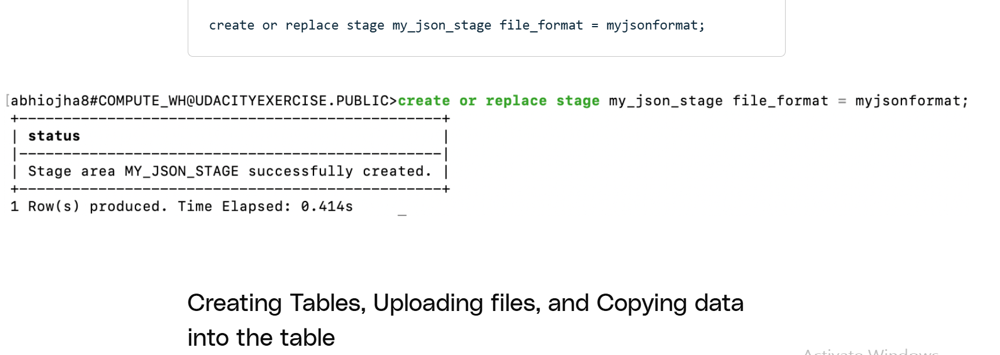

https://www.youtube.com/watch?v=gBHZUegGqCQ

Create a table with one column of type variant.

create table userdetails(userjson variant);

## Exercise: Loading Small Data Files using SnowSQL Client

Loading small data files

In this exercise, you will create a database, schema, and tables in Snowflake and upload CSV files in the database tables using the SnowSQL client.

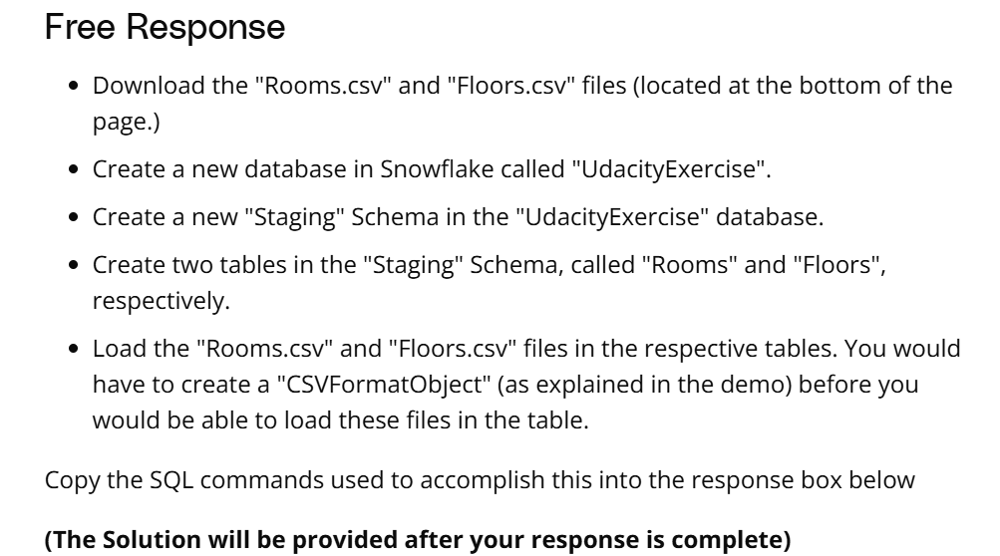

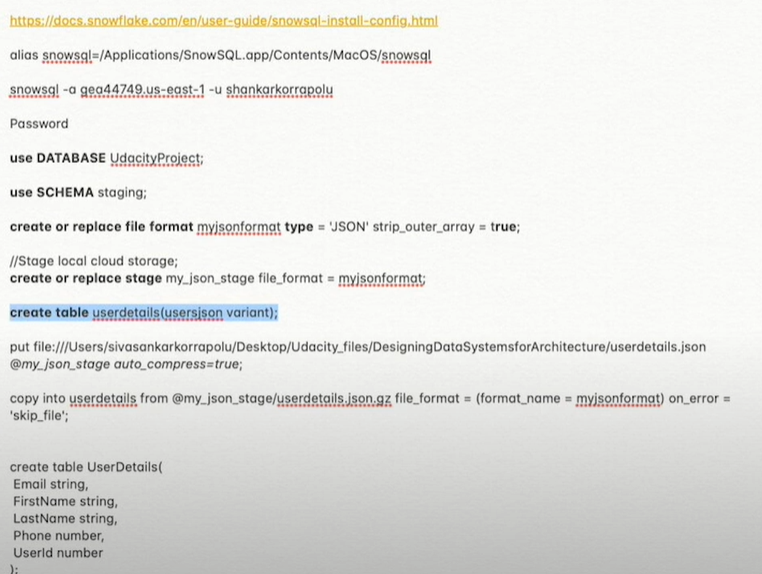

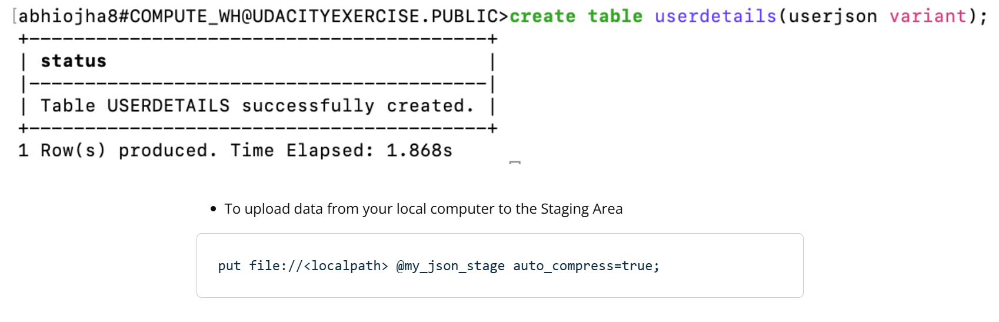

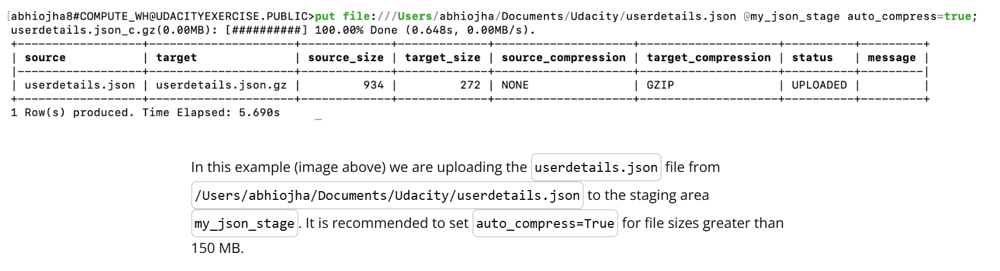

Finally copy the data you just uploaded to the staging area into the table

copy into userdetails from @my_json_stage/userdetails.json.gz file_format=myjsonformat on_error='skip_file';


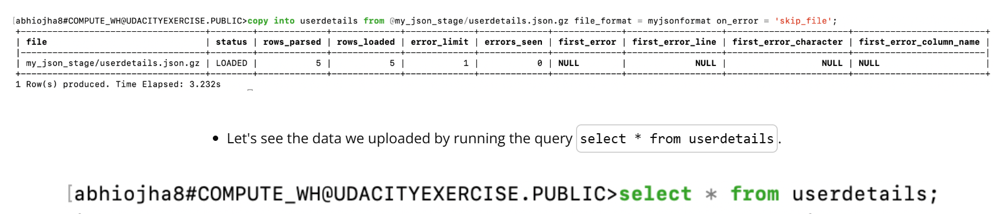

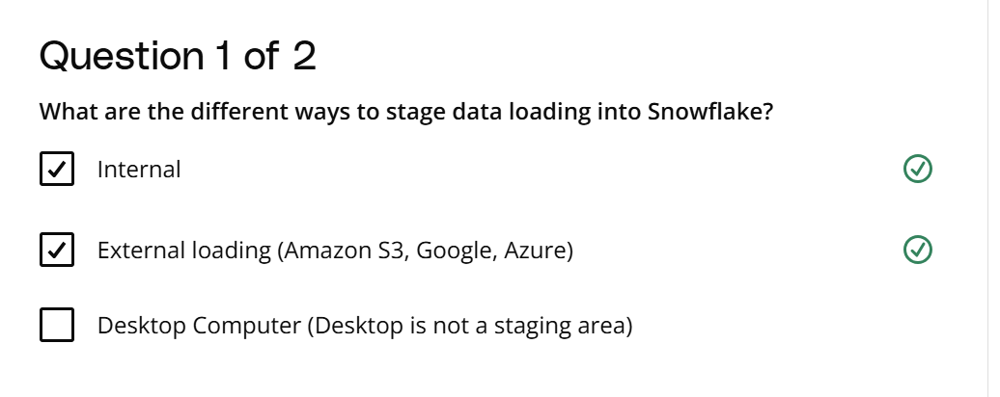

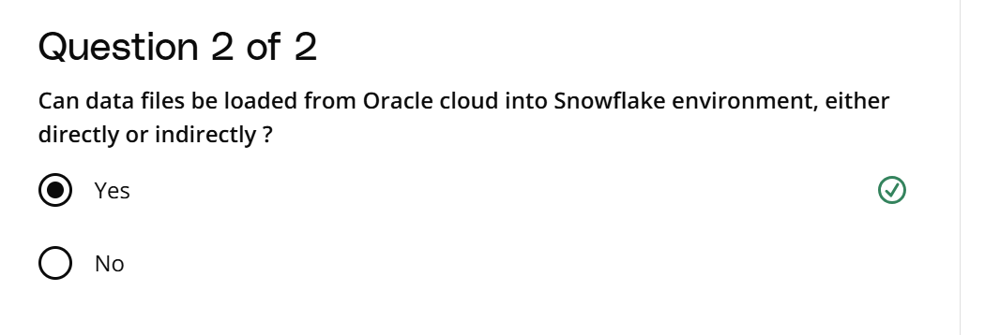

## Exercise Solution Loading Small Files

Loading Small Files in Snowflake using SnowSQL

Open the "SnowSQL" client that you set up on the page "Demo: Getting Started in Snowflake" in the "Data Architecture" Lesson, and execute the following commands.

Creating a Database, if not already

Create a new database or use an existing database

/ *Create a new database or use an existing database* /
CREATE DATABASE UDACITYEXERCISE;
SHOW DATABASES;
USE DATABASE UDACITYEXERCISE;

Create "STAGING" schema in the "UDACITYEXERCISE" database

/ *Create a schema or use an existing schema* /
CREATE SCHEMA STAGING;
/ *Full qualifiying name* /
CREATE SCHEMA "UDACITYEXERCISE"."STAGING";
USE SCHEMA STAGING;

Tip: The SQL command keywords are case-insensitive.

Creating Floors

Create a table with the same columns as that of the CSV file. Create "FLOORS" table in the "STAGING" Schema of "UDACITYEXERCISE" database

/ *Drop if exists* /
DROP TABLE IF EXISTS LargeDataTable; 
/ *Create a new table. You can choose full qualifiying name or just the table name* /
CREATE TABLE "UDACITYEXERCISE"."STAGING"."FLOORS" ("FLOORID" INTEGER, "FLOORNAME" STRING, "BUILDINGID" INTEGER);

The "FLOORS" table contains three columns with headers "FLOORID", "FLOORNAME" and "BUILDINGID", respectively. The column names and data types are chosen to be in accordance with the "floors.csv" file.

Before we can load data in the table created above, we need to create a file format object and a staging area.

/ *Create a simple file format*/
create or replace file format mycsvformat  type='CSV' compression='auto' field_delimiter=',' record_delimiter = '\n' skip_header=1 error_on_column_count_mismatch=true null_if = ('NULL', 'null') empty_field_as_null = true;
/ *If you wish to add more options to the file format* /
CREATE FILE FORMAT "UDACITYEXERCISE"."STAGING".MYCSVFILEFORMAT TYPE = 'CSV' COMPRESSION = 'AUTO' FIELD_DELIMITER = ',' RECORD_DELIMITER = '\n' SKIP_HEADER = 1 FIELD_OPTIONALLY_ENCLOSED_BY = 'NONE' TRIM_SPACE = FALSE ERROR_ON_COLUMN_COUNT_MISMATCH = TRUE ESCAPE = 'NONE' ESCAPE_UNENCLOSED_FIELD = '\134' DATE_FORMAT = 'AUTO' TIMESTAMP_FORMAT = 'AUTO' NULL_IF = ('\\N');
/ *Create a staging area* /
create or replace stage my_csv_stage file_format = mycsvformat;

Now, it's time to load the data in respective tables. We will first "PUT" data in "MY_CSV_STAGE" and then copy it from "MY_CSV_STAGE" to the tables. Let us start with loading data present in "floors.csv" in the FLOORS table.

/ *Put the file from local to the staging area* /
/ *Change the path of the floors.csv, as applicable to you* /
PUT file:///Users/udacity/Downloads/floors.csv @MY_CSV_STAGE AUTO_COMPRESS=TRUE;

Note: Change the path of the floors.csv, as applicable to you. The above "PUT" command uploads the data from the local machine to a staging area. The command above will create floors.csv.gz file in the staging area, that we will use in the next command.

Next, copy the data from "MY_CSV_STAGE" to the FLOORS table as follows:

/ *Copy data from the staging area to the table* /
copy into floors from @my_csv_stage/floors.csv.gz file_format=mycsvformat ON_ERROR = 'CONTINUE' PURGE = TRUE;

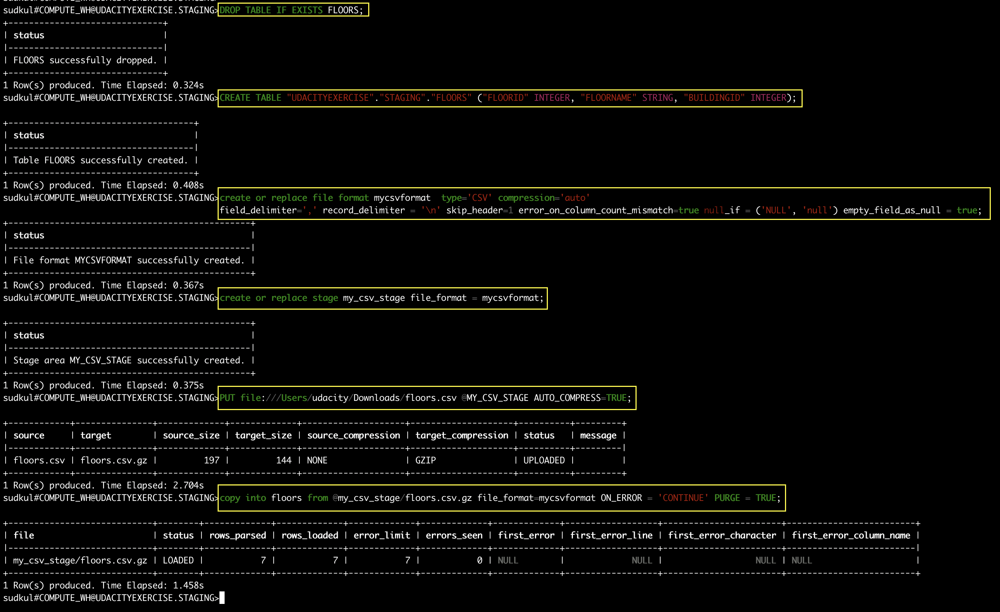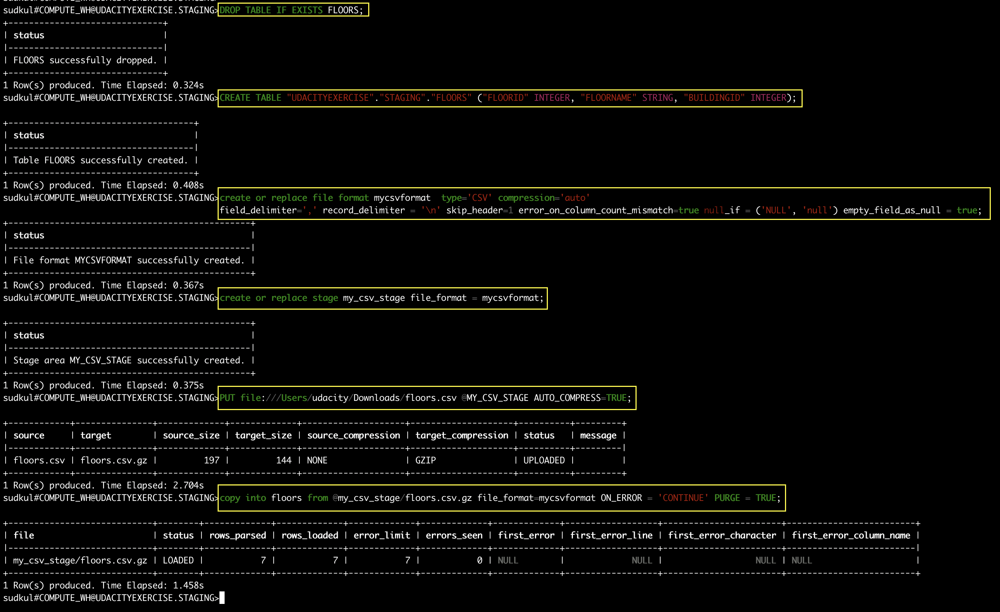

Creating Rooms

Create "ROOMS" table in the "STAGING" Schema of "UDACITYEXERCISE" database

DROP TABLE IF EXISTS rooms; 
/ *Assuming you are in "UDACITYEXERCISE"."STAGING". If not use the qualified name of the table* /
CREATE TABLE "UDACITYEXERCISE"."STAGING"."ROOMS" ("ROOMID" INTEGER, "ROOMNAME" STRING, "FLOORID" INTEGER, "BUILDINGID" INTEGER, "TOTALAREA" DOUBLE, "CLEANEDAREA" DOUBLE);

We need to repeat the same steps for uploading data from "rooms.csv" to the "ROOMS" table:

/ *Assuming `mycsvformat` and `my_csv_stage` are already in place.* /
/ *Put the file from local to the staging area* /
put file:///Users/udacity/Downloads/rooms.csv @my_csv_stage auto_compress=true;

Note: Change the path of the floors.csv, as applicable to you. The command above will create rooms.csv.gz file in the staging area.

Copy data from the staging area to the table

copy into rooms from @my_csv_stage/rooms.csv.gz file_format=mycsvformat ON_ERROR = 'CONTINUE' PURGE = TRUE;

See the commands for creating the Rooms table in the snapshot below.

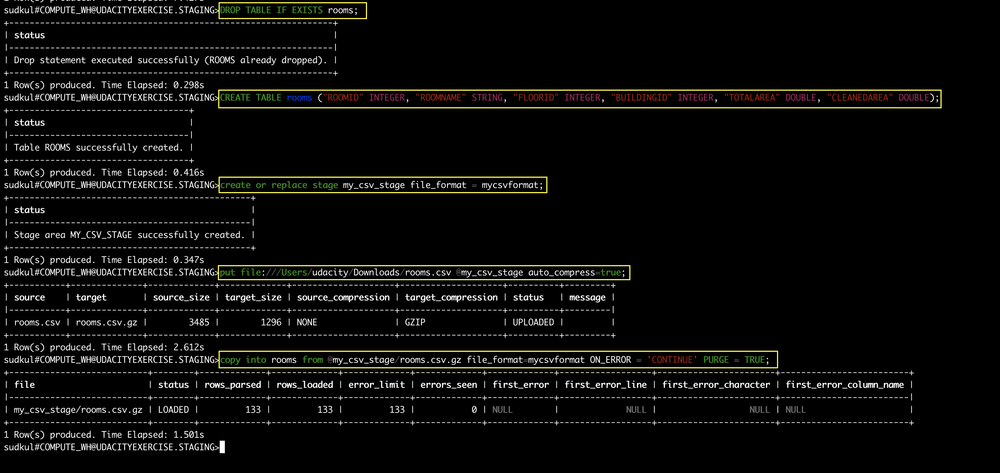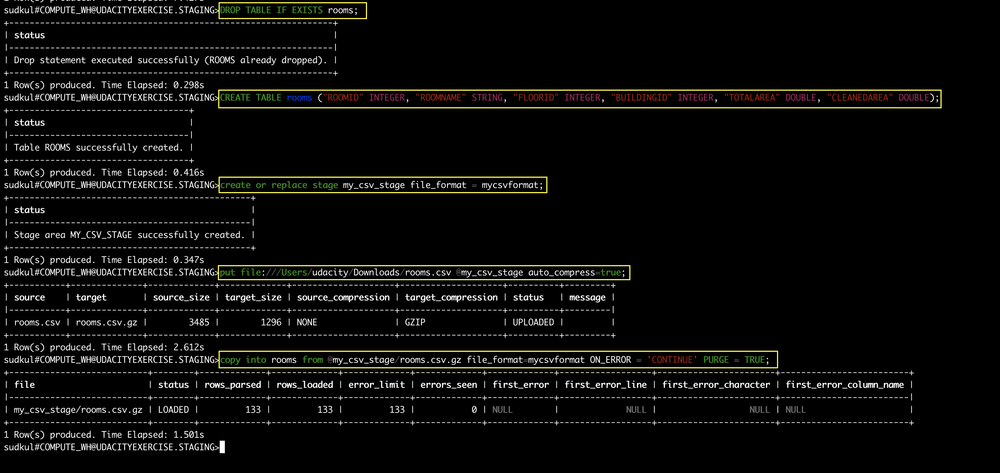

Creating Rooms table in the same database where Floors table is present

Once you are done uploading the data you can view both the table by executing:

/ *List all tables*/
SHOW TABLES;
/ *Show content of a single table.* /
SELECT * FROM FLOORS;

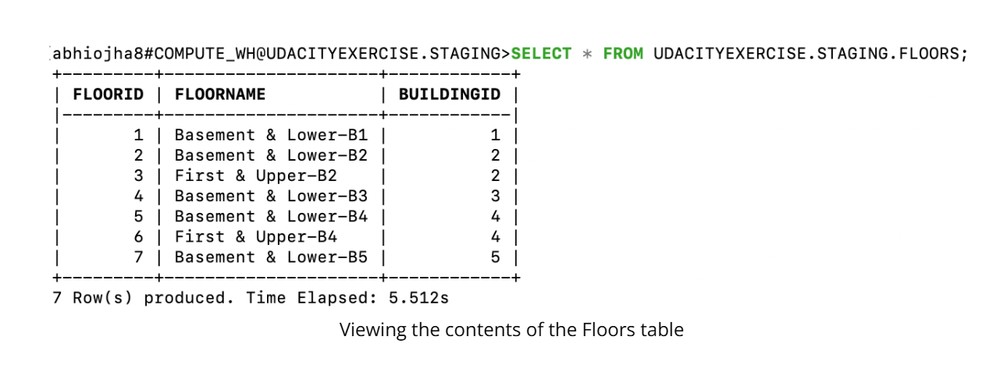

## Practice: Loading Large Data Files in Snowflake

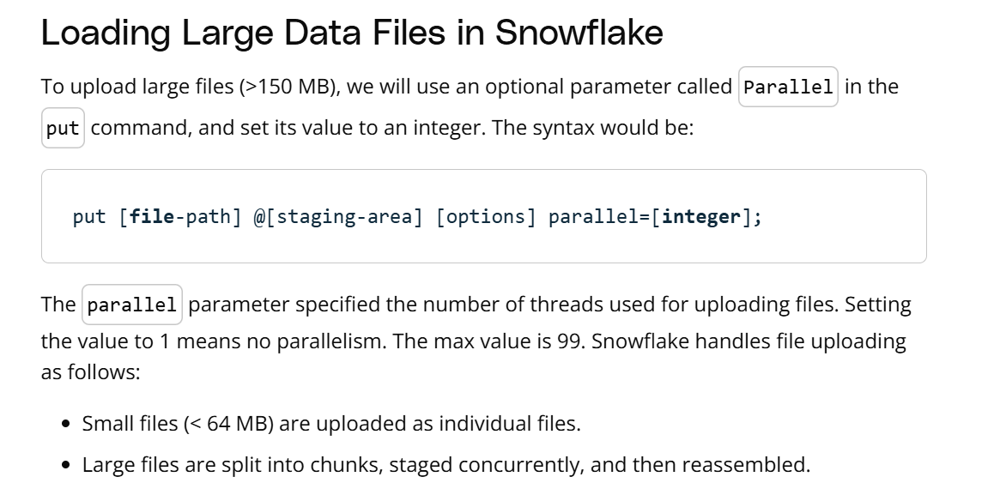

Upload a large file in Snowflake using Optional Parameter Parallel
Open the SnowSQL client and follow the steps below:

Create a database and schema, if not already.

/ *Run any of these commands, as you need them.* /
/ *Create a new database or use an existing database* /
CREATE DATABASE UDACITYEXERCISE;
SHOW DATABASES;
USE DATABASE UDACITYEXERCISE;
/ *Create a schema or use an existing schema* /
CREATE SCHEMA STAGING;
USE SCHEMA STAGING;

Create a new table with the same column count and names as that of the CSV file. You will have to open up the CSV file in your local editor to view the headers.

DROP TABLE IF EXISTS LargeDataTable; 
/ *Create table*/
create table "LargeDataTable" ("pickup_datetime" STRING, "dropoff_datetime" STRING, "Pickup_longitude" DOUBLE, "Pickup_latitude" DOUBLE, "Dropoff_longitude" DOUBLE, "Dropoff_latitude" DOUBLE, "Trip_distance" DOUBLE, "Fare_amount" DOUBLE);

Create a CSV file format object.

create or replace file format mycsvformat type='CSV' compression='auto'
field_delimiter=',' record_delimiter = '\n'  skip_header=1 error_on_column_count_mismatch=true null_if = ('NULL', 'null') empty_field_as_null = true;

Create the staging area.

Upload the file to the staging area:

/ *Put the file from local to the staging area* /
/ *Change the large.csv file path as present in your local machine*/
put file:///Users/udacity/Downloads/large.csv @my_large_data_stage auto_compress=true parallel=4;

Note the use of the optional parameter parallel here. We have set a value of 4, so the data is divided into 4 chunks, which are uploaded in parallel. These chunks are used to reconstruct the original data once the upload is complete. You must replace file path as applicable to you.

The previouos command will create large.csv.gz file in the staging area. Copy data from the staging area to the table:

copy into "LargeDataTable" from @my_large_data_stage/large.csv.gz file_format=mycsvformat on_error='skip_file';

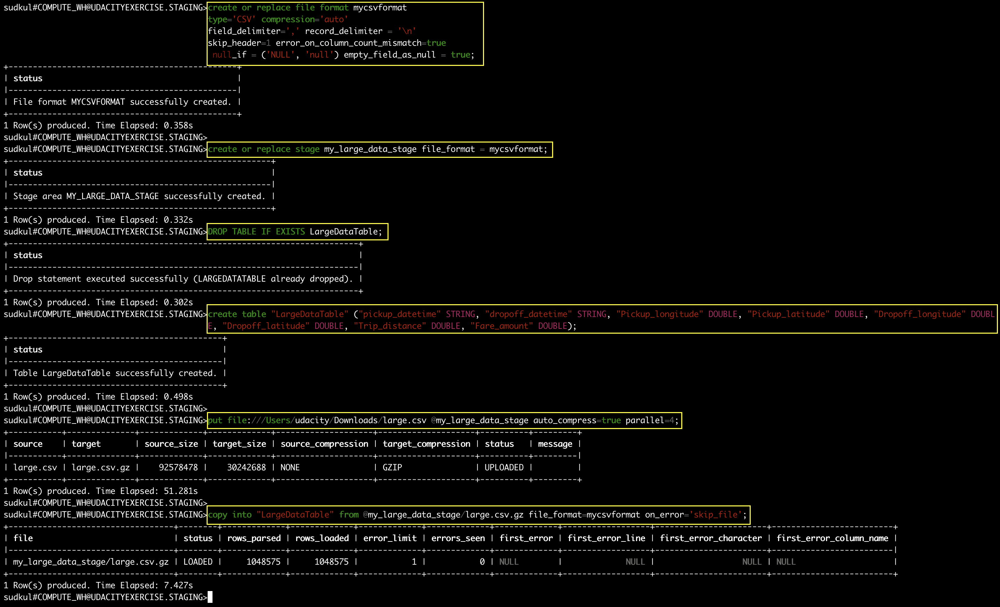

## Quiz: Cloud Storage

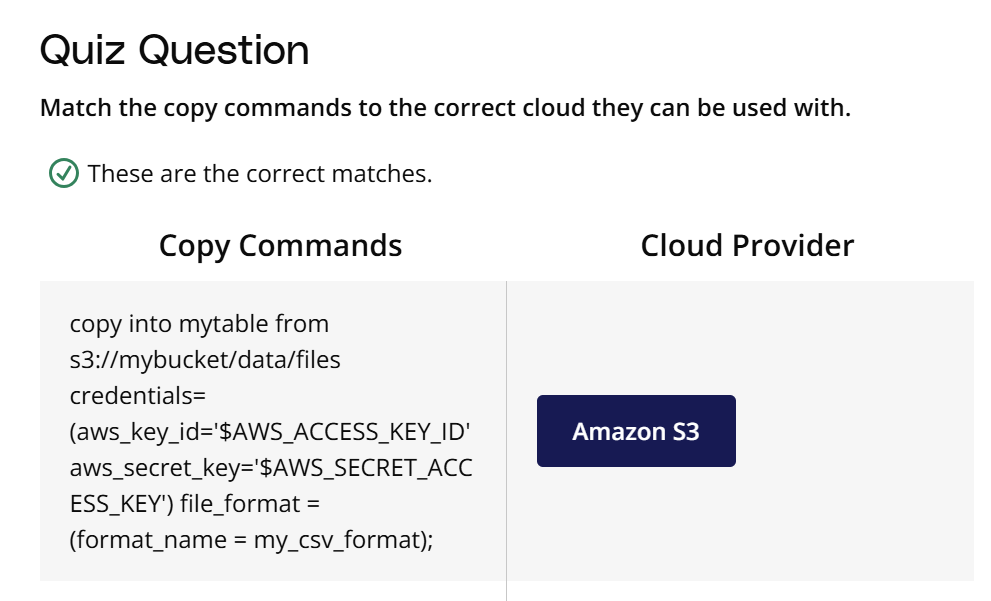

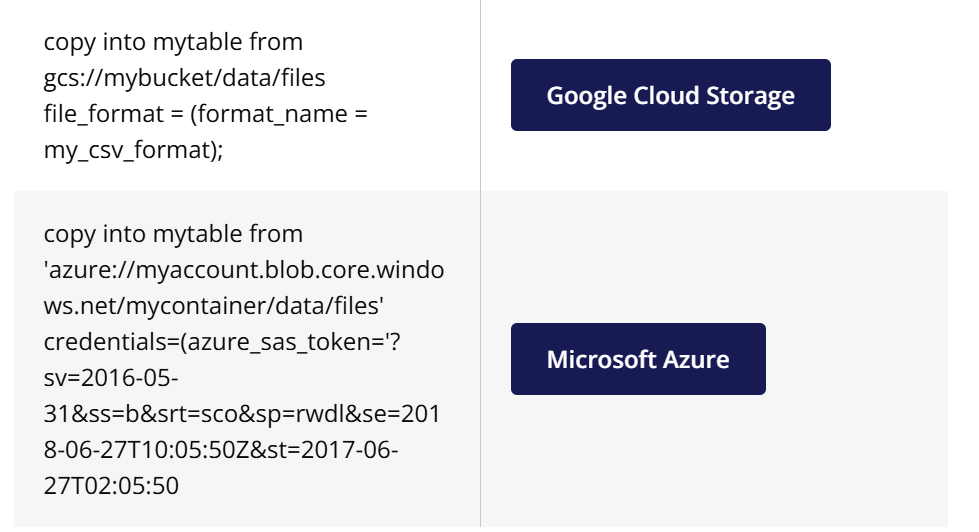

## Create a Schedule

https://www.youtube.com/watch?v=vWtRNbjDuqY

## Scheduling Data Ingestion
All source files have to be scheduled to ingest into the staging database. Both the initial ingestions, as well as on-going refreshes is an important consideration for staging data. Not only is the size of the data a factor, but also the type of data, and how that data is used.

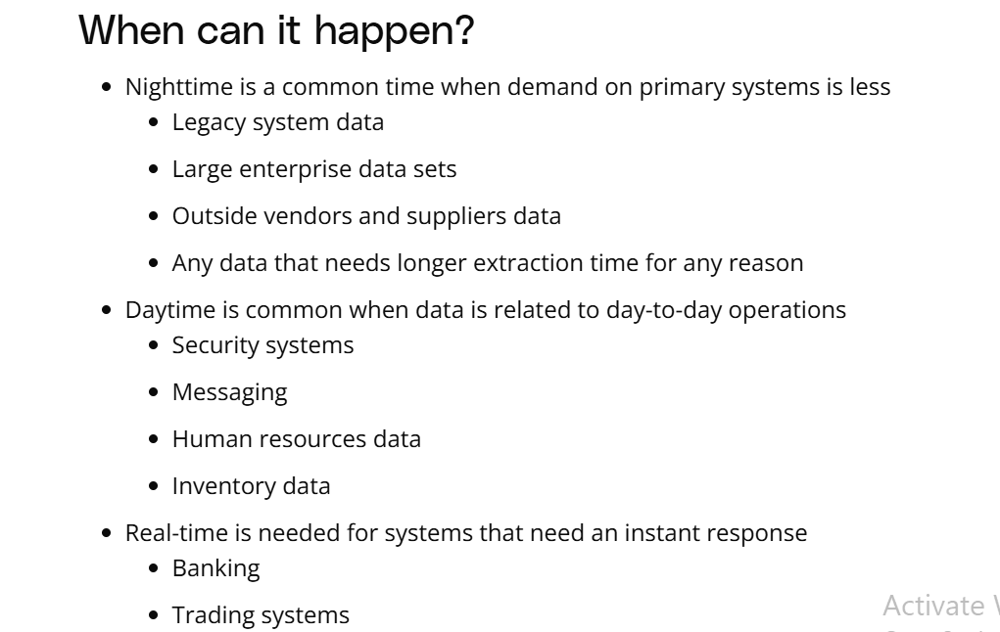

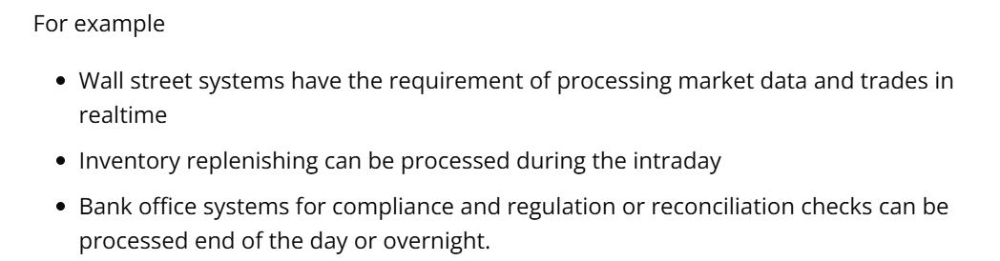

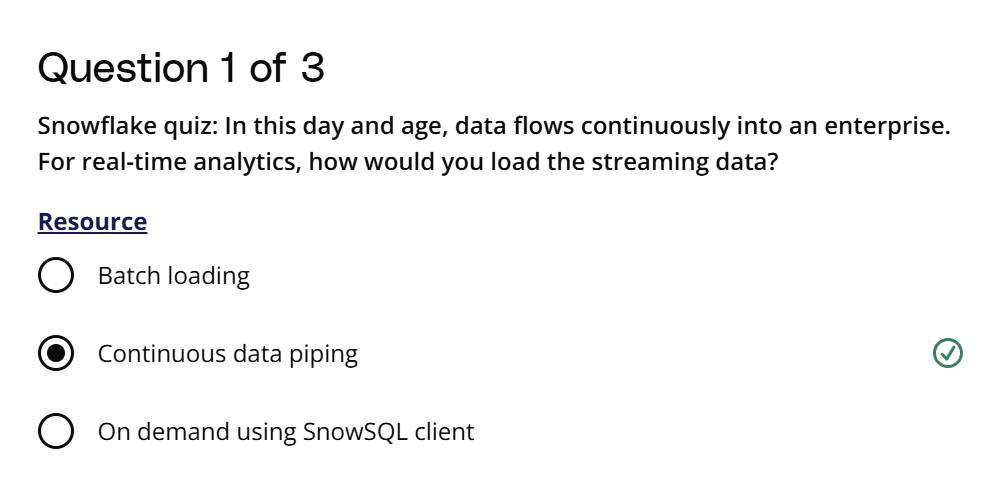

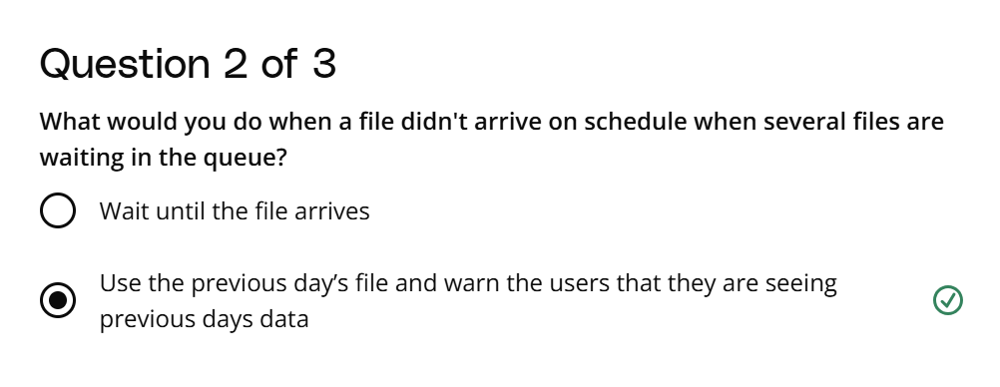

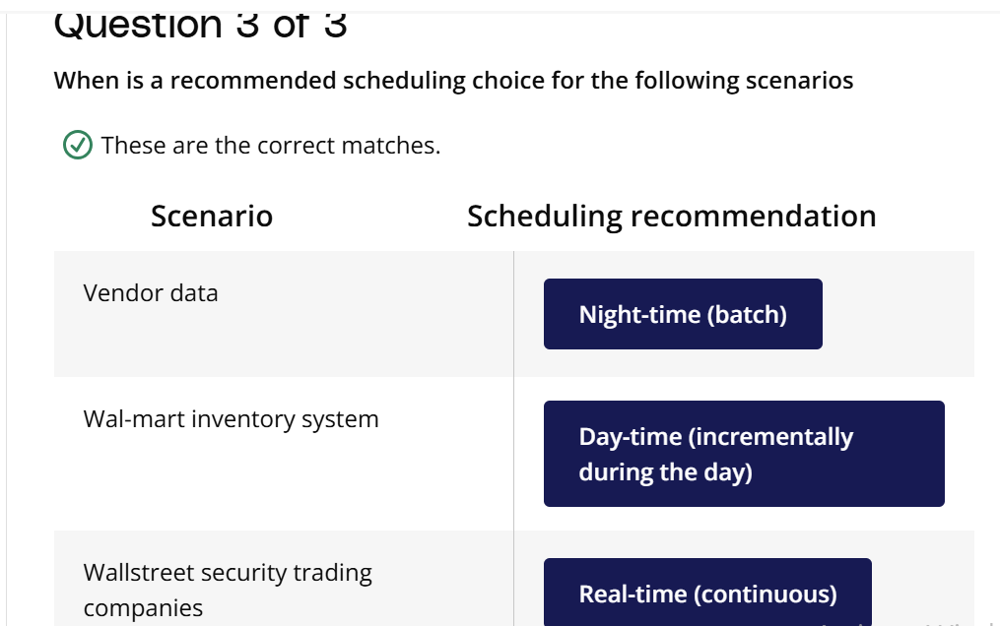

## Create a Metadata Schema

https://www.youtube.com/watch?v=pwWEUJqv5u4

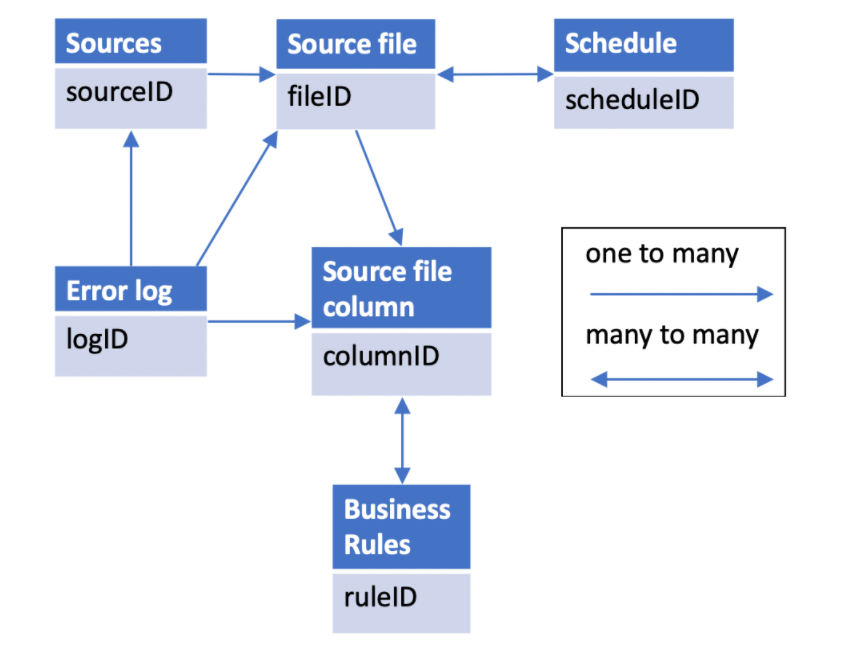

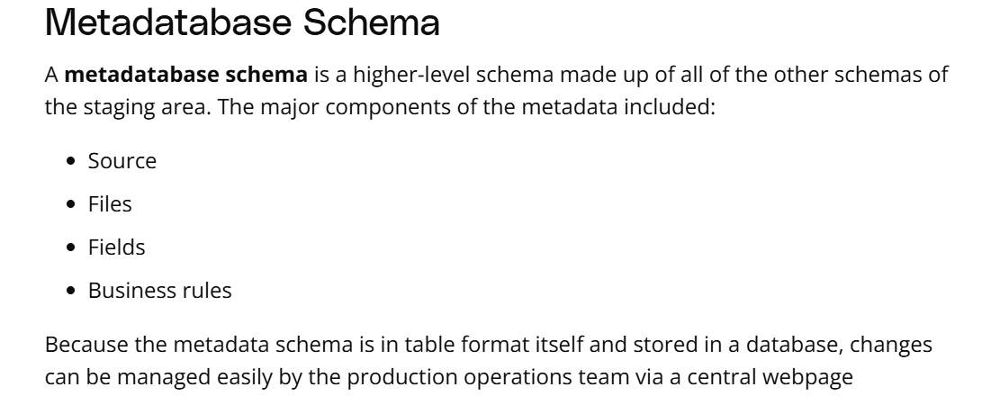

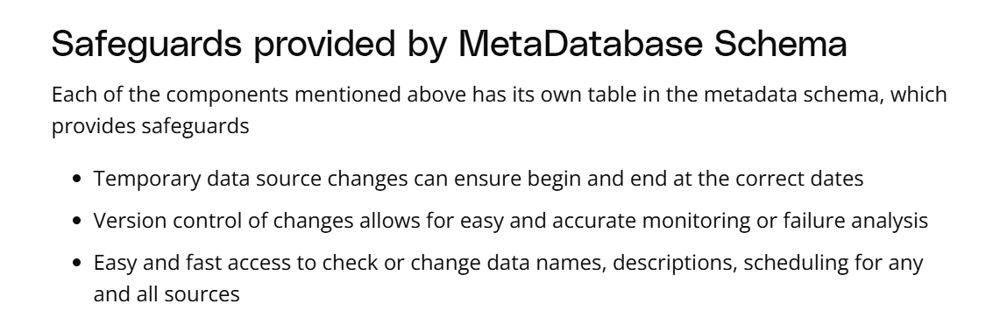

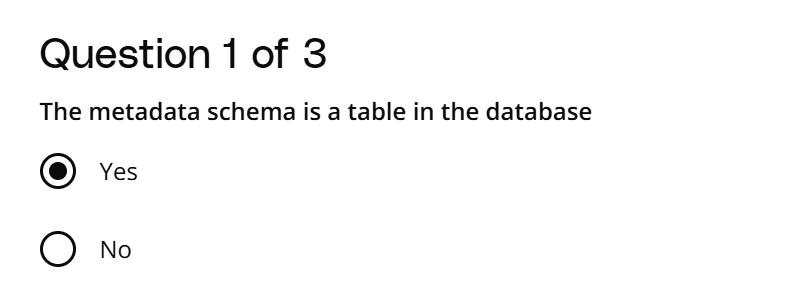

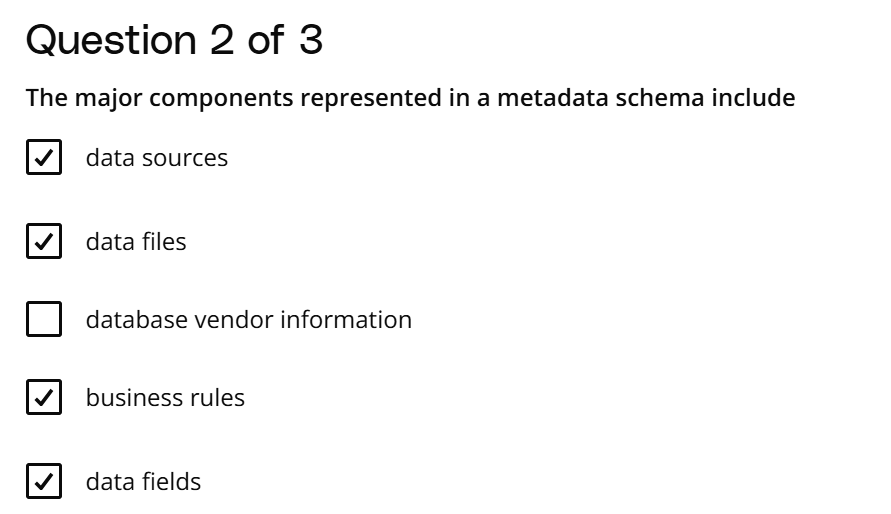

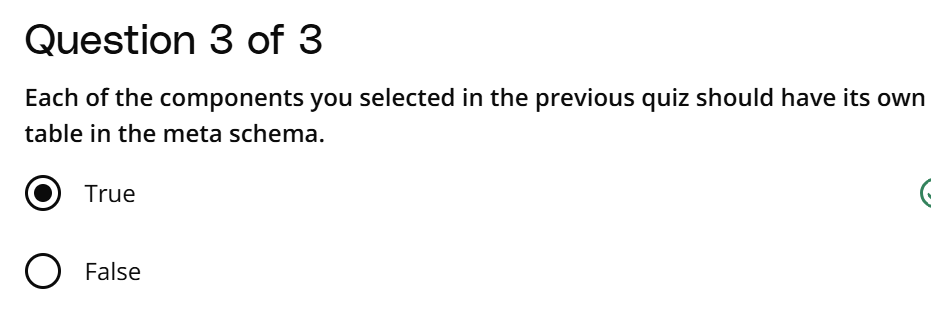

Exercise: Metadata tables for business and technology users

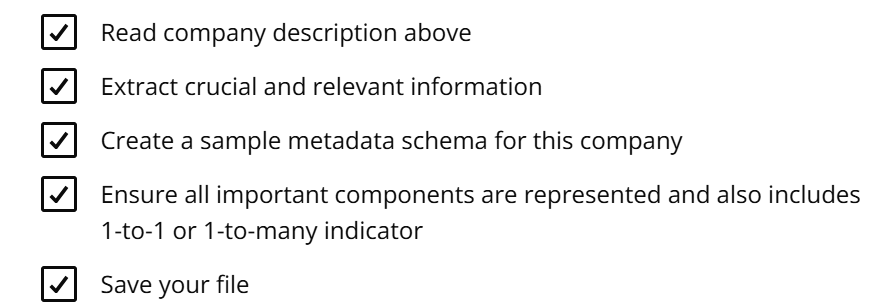

## Create Ingestion Techniques

https://www.youtube.com/watch?v=EpUXbQ_ojHM

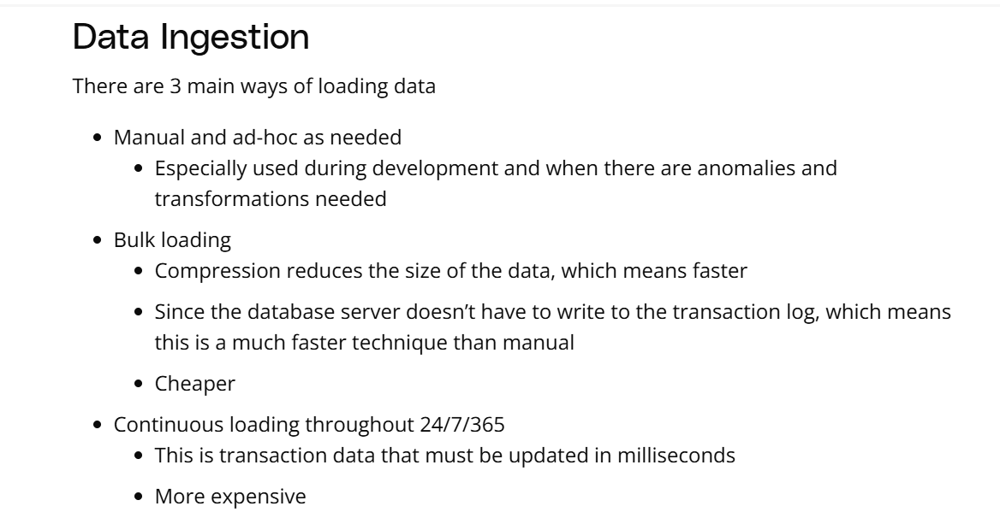

Drowning in Data

Humans generate 2.5 quintillion bytes of data every single day. Experts predict by 2025, we will reach over 400 exabytes.

This is important because the companies that deal with data have to handle the increasing data demands. As a Data Architect, you must manage the data before it becomes unmanageable.

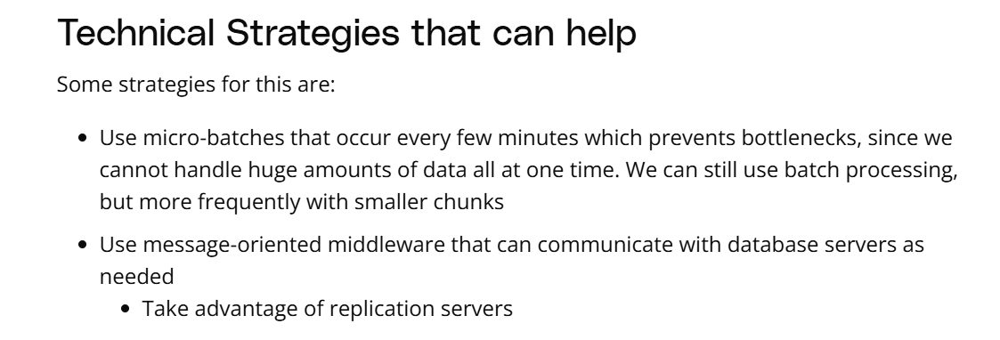

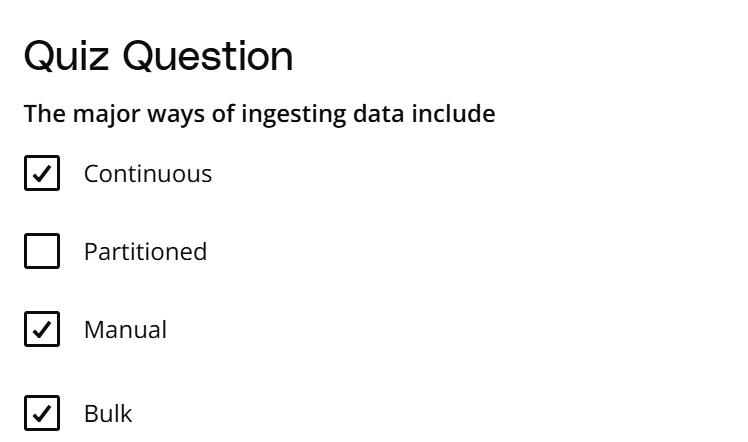

## Edge Cases

https://www.youtube.com/watch?v=_UFzrCVAzNM

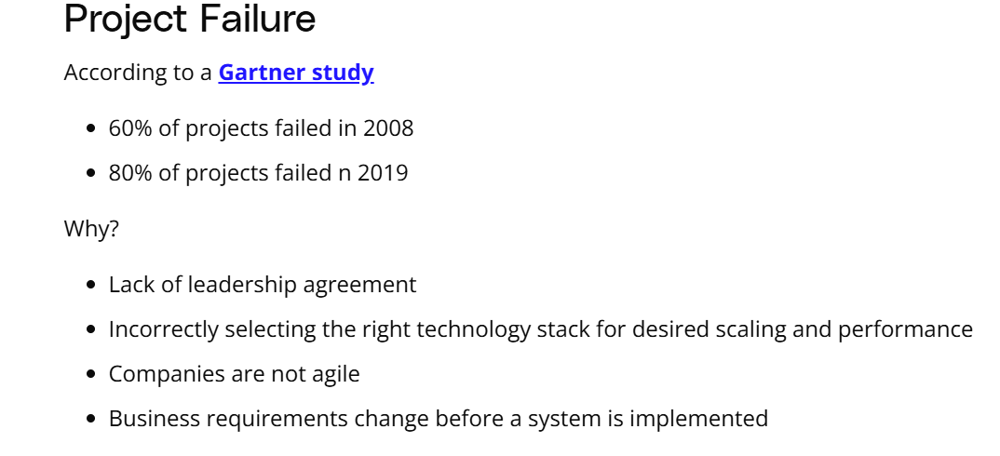

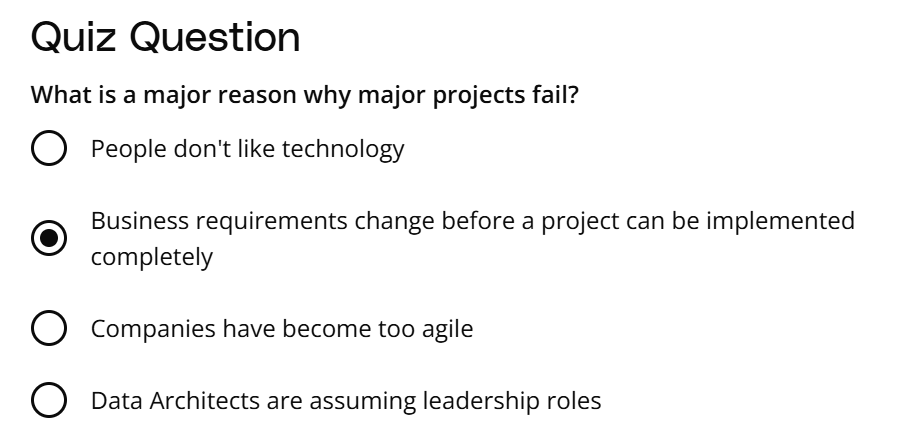

## How Experts Think About Staging

https://www.youtube.com/watch?v=G4gPkkWeuuE

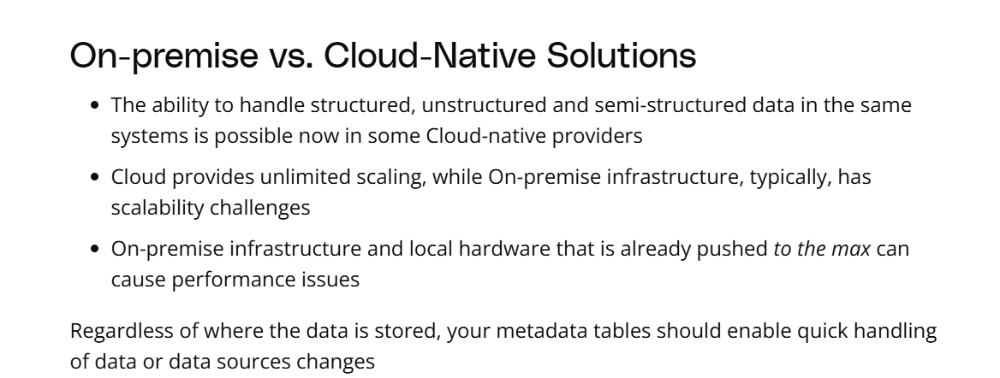

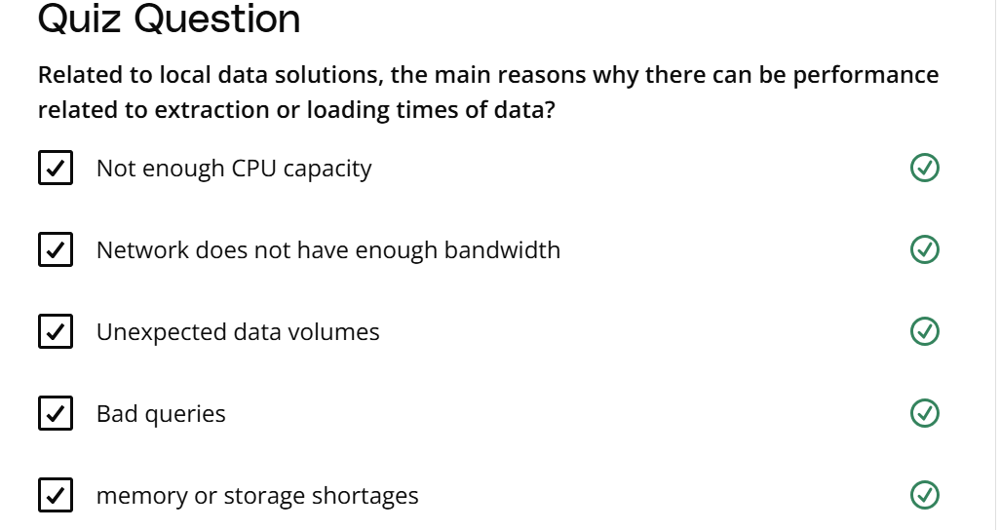

## Lesson Review

https://www.youtube.com/watch?v=91BiJb_Uggs

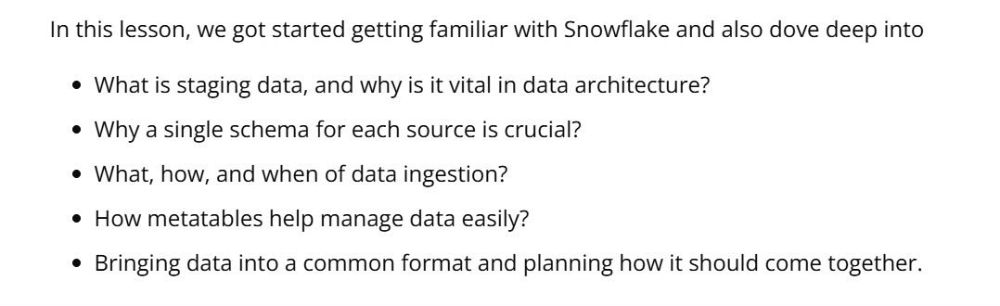

## Glossary

Ad Hoc loading	In emergency situations, when automation is not available, use this technique
Bulk Ingestion	Ingesting large amounts of data at intervals
Business Rules	Rules that are in place to manage access, ingestion, reporting, and updating of data
Continuous ingestion	Ingesting data in an ongoing manner, such as in real-time
Ingestion	Absorbing the incoming data at any speed at any volume
Metadata Schema	Data about data. Describes tables, columns, and business rules of all schemas
One Source Once Schema	In the staging area, it is easy to manage with one scheme for one source system.
Pull	In batch processing systems, data is being pulled on scheduled times
Push	In real-time streaming systems, data being pushed to downstream systems as and when it is available.
Schema	Logically group of tables, views, functions, stored procedures, and security roles
Separation of Concerns	Divide and conquer makes us think and solve data problems in a smaller context
Staging	An intermediate storage area before transforming and cleansing of data
Yottabyte	1000 Zettabytes
Zettabyte	1000 exabytes


## Additional Learning and Resources

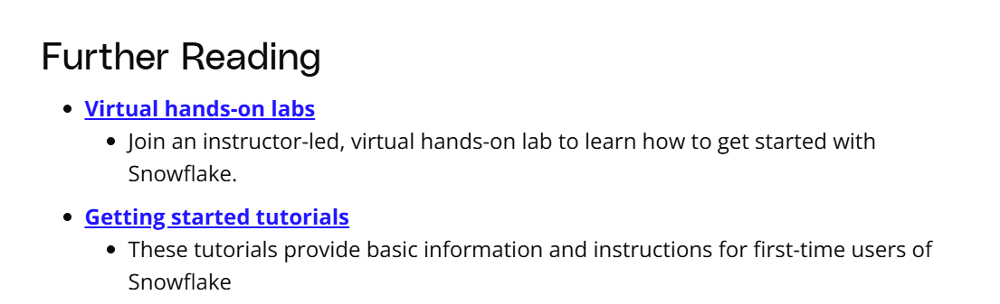

https://www.snowflake.com/virtual-hands-on-lab/

https://docs.snowflake.com/en/user-guide-getting-started.html